# Лабораторна робота 1 (складний рівень)
Дані: SaveEcoBot, пост № 24169 (Київ), 01.01.2025 – 27.11.2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Завантаження даних

In [2]:
raw = pd.concat([pd.read_csv(f) for f in ["saveecobot_24169_2025.csv", "saveecobot_24169_2026.csv"]], ignore_index=True)
print(raw.shape)
raw.head()

(1698107, 5)


,device_id,phenomenon,value,logged_at,value_text
0,24169,co2_mg,829.0827,2025-01-01 00:00:00,NaN
1,24169,co2_ppm,429.2000,2025-01-01 00:00:00,NaN
2,24169,co_ppb,256.2400,2025-01-01 00:00:00,NaN
3,24169,co_ug,315.0263,2025-01-01 00:00:00,NaN
4,24169,formaldehyde_ppb,0.0000,2025-01-01 00:00:00,NaN


## 2. Підготовка даних
Перетворюємо дати, видаляємо порожню колонку і дублікати, переводимо в широкий формат, нулі газових датчиків (збої) і викиди (> 99.9 перцентиля) замінюємо на NaN, усереднюємо по годинах.

In [3]:
df = raw.drop(columns=["value_text", "device_id"]).drop_duplicates()
df["logged_at"] = pd.to_datetime(df["logged_at"])

COLS = {"pm25": "PM2.5", "pm10": "PM10", "co_ppb": "CO", "no_ppb": "NO", "no2_ppb": "NO2", "o3_ppb": "O3"}
data = df.pivot_table(index="logged_at", columns="phenomenon", values="value")[list(COLS)].rename(columns=COLS)

data[["CO", "NO2"]] = data[["CO", "NO2"]].replace(0, np.nan)
data = data.where(data <= data.quantile(0.999))

hourly = data.resample("1h").mean().dropna(subset=["PM2.5"])
hourly["hour"] = hourly.index.hour
print(hourly.shape)
print(hourly.isna().sum())

(14766, 7)
phenomenon
PM2.5       0
PM10        0
CO       3028
NO          8
NO2         8
O3          8
hour        0
dtype: int64


## 3. Залежності між забруднювачами

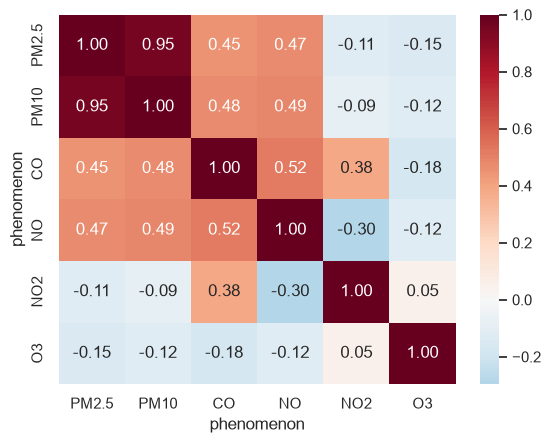

In [4]:
cols = ["PM2.5", "PM10", "CO", "NO", "NO2", "O3"]
sns.heatmap(hourly[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.show()

In [5]:
rows = []
for x in ["CO", "NO", "NO2", "O3"]:
    d = hourly[["PM2.5", x]].dropna()
    m = sm.OLS(d["PM2.5"], sm.add_constant(d[x])).fit()
    rows.append({"модель": f"PM2.5 ~ {x}", "b0": m.params["const"], "b1": m.params[x], "R2": m.rsquared, "p-value": m.pvalues[x]})
pd.DataFrame(rows).round(4)

,модель,b0,b1,R2,p-value
0,PM2.5 ~ CO,1.5216,0.0416,0.2007,0.0
1,PM2.5 ~ NO,9.3101,0.4029,0.2238,0.0
2,PM2.5 ~ NO2,16.1026,-0.1252,0.0131,0.0
3,PM2.5 ~ O3,14.5475,-0.1339,0.0221,0.0


## 4. Регресійні моделі
Навчальна вибірка — 2025 рік, тестова — 2026 рік.

In [6]:
train = hourly[hourly.index.year == 2025]
test = hourly[hourly.index.year == 2026]
results = []

def fit_eval(name, make_X, y="PM2.5", need=()):
    tr, te = train.dropna(subset=[y, *need]), test.dropna(subset=[y, *need])
    model = LinearRegression().fit(make_X(tr), tr[y])
    pred = model.predict(make_X(te))
    results.append({"модель": name, "RMSE": mean_squared_error(te[y], pred) ** 0.5, "R2": r2_score(te[y], pred)})
    return model

### 4a. Залежність PM2.5 від часу доби

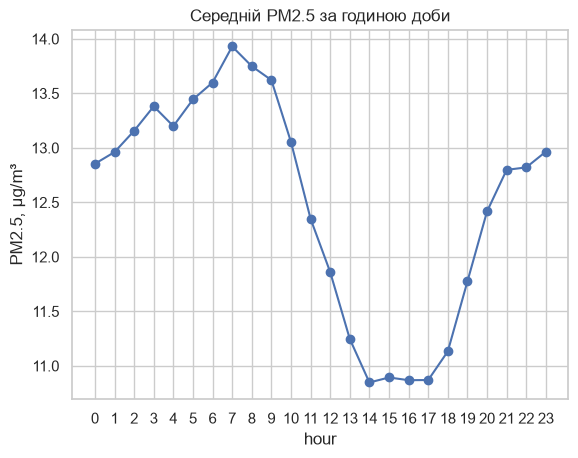

In [7]:
hourly.groupby("hour")["PM2.5"].mean().plot(marker="o", xticks=range(24), ylabel="PM2.5, µg/m³", title="Середній PM2.5 за годиною доби")
plt.show()

In [8]:
# Ранок (06–09) проти ночі (00–04) в межах одного дня, парний t-тест
day = hourly.index.date
night = hourly[hourly["hour"].between(0, 4)].groupby(day[hourly["hour"].between(0, 4)])["PM2.5"].mean()
morning = hourly[hourly["hour"].between(6, 9)].groupby(day[hourly["hour"].between(6, 9)])["PM2.5"].mean()
d = pd.concat([night, morning], axis=1, keys=["ніч", "ранок"]).dropna()

print(f"Днів: {len(d)}, ніч: {d['ніч'].mean():.2f}, ранок: {d['ранок'].mean():.2f}")
print(f"Ранок брудніший у {(d['ранок'] > d['ніч']).mean():.0%} днів, p-value = {stats.ttest_rel(d['ранок'], d['ніч']).pvalue:.4f}")

Днів: 611, ніч: 13.11, ранок: 13.78
Ранок брудніший у 59% днів, p-value = 0.0064


In [9]:
hour_X = lambda d: pd.get_dummies(pd.Categorical(d["hour"], categories=range(24)), drop_first=True).astype(float)
fit_eval("PM2.5 ~ година доби", hour_X);

### 4b. Залежність одного забрудника від іншого

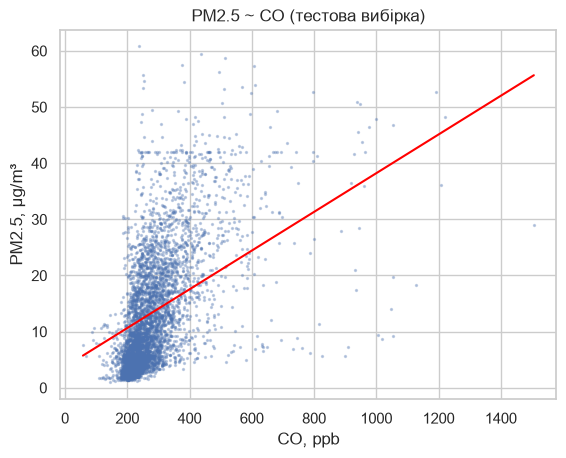

In [10]:
fit_eval("PM2.5 ~ CO", lambda d: d[["CO"]], need=["CO"])
fit_eval("PM2.5 ~ NO", lambda d: d[["NO"]], need=["NO"])

te = test.dropna(subset=["CO"])
m = LinearRegression().fit(train.dropna(subset=["CO"])[["CO"]], train.dropna(subset=["CO"])["PM2.5"])
plt.scatter(te["CO"], te["PM2.5"], s=2, alpha=.3)
xs = np.linspace(te["CO"].min(), te["CO"].max(), 50)
plt.plot(xs, m.predict(pd.DataFrame({"CO": xs})), color="red")
plt.xlabel("CO, ppb"); plt.ylabel("PM2.5, µg/m³"); plt.title("PM2.5 ~ CO (тестова вибірка)")
plt.show()

## 5. Оцінка моделей (тестова вибірка)

In [11]:
pd.DataFrame(results).round(3)

,модель,RMSE,R2
0,PM2.5 ~ година доби,9.774,-0.078
1,PM2.5 ~ CO,8.861,0.267
2,PM2.5 ~ NO,8.290,0.224


## 6. Висновки
* PM2.5 помірно пов'язаний з CO і NO (R² ≈ 0.2): ймовірно, у них спільне джерело — згоряння палива. З NO₂ і O₃ зв'язку майже немає (R² < 0.03).
* Гіпотеза «зранку брудніше, ніж уночі» підтверджується статистично (p < 0.05), але різниця мала (~5%). Найчистіше повітря вдень.
* Модель від часу доби має R² < 0, тобто година доби сама по собі майже не пояснює рівень PM2.5.
* Моделі PM2.5 ~ CO і PM2.5 ~ NO на тестових даних мають R² ≈ 0.22–0.27 і RMSE ≈ 8–9 µg/m³: залежність є, але слабка.

**Припущення:** нулі газових датчиків вважаємо збоями; використано дані лише одного поста; регресія показує зв'язок, а не причинність.